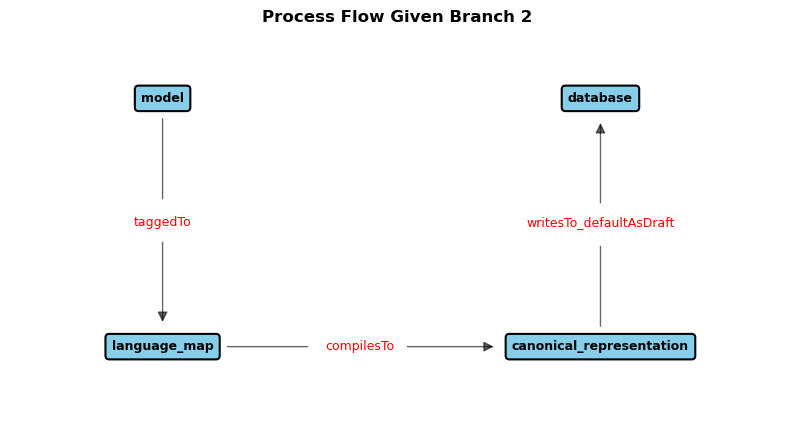

In [18]:
from diagram import StructuredGraphBuilder

builder = StructuredGraphBuilder()
# Primary RDF
builder.add_entity("model", label="model", pos=(-1, 1))
builder.add_entity("language_map", label="language_map", pos=(-1, -1))
builder.add_entity("canonical_representation", label="canonical_representation", pos=(1, -1))
builder.add_entity("database", label="database", pos=(1,1))
hasOwnership_rel_id = builder.add_reified_edge(source="language_map", rel_name="compilesTo", target="canonical_representation", rel_pos=(-.1, -1),)
builder.add_reified_edge(source="model", rel_name="taggedTo", target="language_map", rel_pos=(-1, 0),)
builder.add_reified_edge(source="canonical_representation", rel_name="writesTo_defaultAsDraft", target="database", rel_pos=(1, 0),)
builder.draw('Process Flow Given Branch 2', figsize=(10, 5))

candidate subject
draft subject
approved subject
candidate object
draft object
approved object
candidate predicate
draft predicate
approved predicate


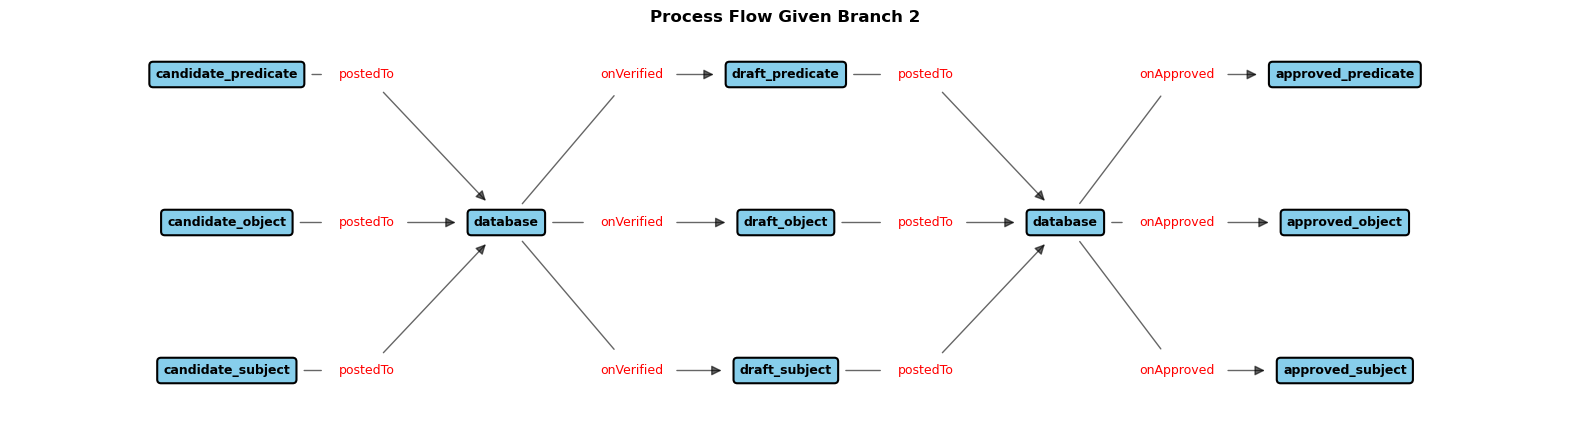

In [83]:
parts = ['subject', 'object', 'predicate']
stages = ['candidate', 'draft', 'approved']
builder = StructuredGraphBuilder()
builder.add_entity("db1", label="database", pos=(1, 2))
builder.add_entity("db2", label="database", pos=(3, 2))
for i, y in enumerate(parts):
    for j, x in enumerate(stages):
        print(x,y)
        builder.add_entity(f"{x}_{y}", label=f"{x}_{y}", pos=(2*j, 2*i))
        if j == 0:
            builder.add_reified_edge(source=f"{x}_{y}", rel_name="postedTo", target="db1", rel_pos=(2*j+0.5, 2*i),)
        elif j == 1:
            builder.add_reified_edge(source="db1", rel_name="onVerified", target=f"{x}_{y}", rel_pos=(1.45, 2*i))
            builder.add_reified_edge(source=f"{x}_{y}", rel_name="postedTo", target="db2", rel_pos=(2*j+0.5, 2*i),)
        elif j == 2:
            builder.add_reified_edge(source="db2", rel_name="onApproved", target=f"{x}_{y}", rel_pos=(3.4, 2*i))



builder.draw('Process Flow Given Branch 2', figsize=(20, 5)) 

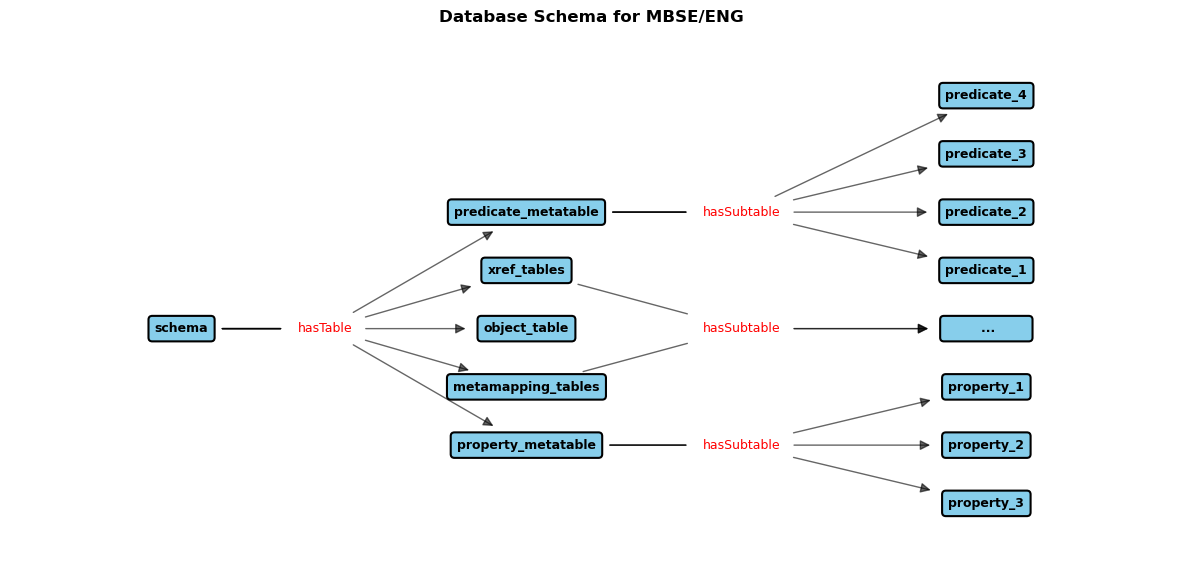

In [134]:
builder = StructuredGraphBuilder()
# Primary RDF
builder.add_entity("schema", label="schema", pos=(-.2, 1))
builder.add_entity("object_table", label="object_table", pos=(1, 1))
builder.add_entity("predicate_metatable", label="predicate_metatable", pos=(1, 2))
builder.add_entity("property_metatable", label="property_metatable", pos=(1, 0))
builder.add_entity("xref_tables", label="xref_tables", pos=(1, 1.5))
builder.add_entity("metamapping_tables", label="metamapping_tables", pos=(1, 0.5))
builder.add_entity("other", label="        ...       ", pos=(2.6, 1))
for i in range(1, 5):
    builder.add_entity(f"predicate_{i}", label=f"predicate_{i}", pos=(2.6, 1+i/2))
    builder.add_reified_edge(source="predicate_metatable", rel_name="hasSubtable", target=f"predicate_{i}", rel_pos=(1.75, 2),)
for j in range(1, 4):
    builder.add_entity(f"property_{j}", label=f"property_{j}", pos=(2.6, 1-j/2))
    builder.add_reified_edge(source="property_metatable", rel_name="hasSubtable", target=f"property_{j}", rel_pos=(1.75, 0),)
for s in ['object_table', 'predicate_metatable', 'property_metatable', 'xref_tables', 'metamapping_tables']:
    builder.add_reified_edge(source="schema", rel_name="hasTable", target=s, rel_pos=(0.3, 1),)
for t in ['xref_tables', 'metamapping_tables']:
    builder.add_reified_edge(source=t, rel_name="hasSubtable", target="other", rel_pos=(1.75, 1),)

builder.draw('Database Schema for MBSE/ENG', figsize=(15, 7))